# Notebook 10 - Target Variable Analysis
Sprint 4 - EDA

The target variable is the column the model must predict, so it deserves its own analysis. My target is Churn (Yes or No), which makes this a binary classification problem. In this notebook I study the class distribution, counts, percentages and imbalance, check the quality of the target, see how a naive model behaves on it, and study how churn changes with tenure. The regression analysis in the assignment (mean, variance, skewness and so on for a numerical target) does not apply to Churn, so at the end I include a short optional preview of MonthlyCharges as a possible regression target.

**Dataset:** Telco Customer Churn (Kaggle, 7043 rows and 21 columns)

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# numeric version of the target for calculations (1 = churned)
y = (df["Churn"] == "Yes").astype(int)

print("Rows:", len(df))
print("Target column: Churn")

Rows: 7043
Target column: Churn


## 1. Why Analyse the Target Before Machine Learning?

**Concept:** Everything in a supervised model is built around the target: the type of model, the loss function, the evaluation metric and the way the data is split. If the target is not understood, a model can look good on paper and still be useless. For classification I need to know how many classes there are, how they are balanced, and whether the labels are clean. For regression I need to know the shape of the distribution, the spread, the skewness and the outliers.

**Example (business):** A hospital wants to predict a rare disease that only 1 in 100 patients has. A model that says healthy for everyone is 99% accurate, but it finds no sick patient. Without looking at the target distribution first, the team could report 99% accuracy as a success.

## 2. Class Distribution, Counts and Percentages

**Concept:** For a classification target, the class counts show how many examples each class has, and the percentages show the share of each class. The class with more examples is the majority class and the other is the minority class.

**Example (business):** If 1000 customers are checked and 740 stayed and 260 left, the counts are 740 and 260, and the percentages are 74% and 26%.

       count  percent
Churn                
No      5174    73.46
Yes     1869    26.54

Total: 7043


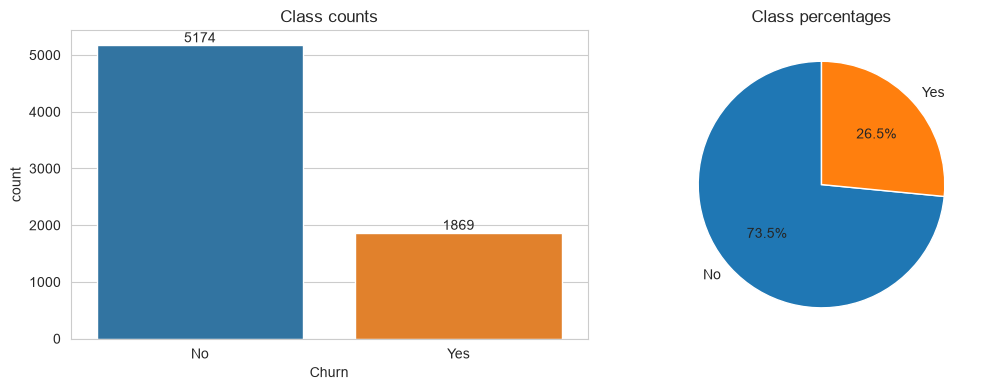

In [10]:
counts = df["Churn"].value_counts()
percent = (df["Churn"].value_counts(normalize=True) * 100).round(2)

class_table = pd.DataFrame({"count": counts, "percent": percent})
print(class_table)
print()
print("Total:", counts.sum())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="Churn", order=["No", "Yes"], hue="Churn", legend=False, ax=axes[0])
for i, c in enumerate(counts[["No", "Yes"]]):
    axes[0].text(i, c + 50, str(c), ha="center")
axes[0].set_title("Class counts")

axes[1].pie(counts[["No", "Yes"]], labels=["No", "Yes"], autopct="%1.1f%%", startangle=90)
axes[1].set_title("Class percentages")

plt.tight_layout()
plt.show()

**What the code does:** It counts the customers in each Churn class, calculates the percentages, prints them in a table, and draws a bar chart with the counts and a pie chart with the percentages.

**Why this method was used:** A count table gives the exact numbers, the bar chart shows the size difference between the classes and the pie chart has only two slices, so it is easy to read as a share of the whole.

**What the output means:** About 5174 customers stayed (No, about 73.5%) and about 1869 customers left (Yes, about 26.5%). The two numbers add up to 7043.

**Insights:** More than 1 in 4 customers left, which is a high churn rate for a subscription business. The No class is almost three times bigger than the Yes class.

**Effect on the ML pipeline:** The majority class will dominate what the model learns, unless I take the imbalance into account. The percentages also give the base rate: a random customer has a 26.5% chance of churning, and a useful model must do better than that.

## 3. Class Imbalance

**Concept:** Class imbalance means that the classes have very different sizes. The imbalance ratio is the majority count divided by the minority count. Different books use different limits, but a common rule is that a minority share of 20% to 40% is mild imbalance, 1% to 20% is moderate and below 1% is extreme. With imbalance, accuracy becomes misleading, because a model can get a high accuracy by always predicting the majority class. Better metrics are precision, recall, F1 and ROC AUC.

**Example (numerical):** In 100 customers with 90 No and 10 Yes, a model that always says No has an accuracy of 90%, a recall of 0% (it finds none of the 10 churners) and an F1 of 0.

In [11]:
majority = counts.idxmax()
minority = counts.idxmin()

print("Majority class:", majority, "| Minority class:", minority)
print("Imbalance ratio:", round(counts.max() / counts.min(), 2), ": 1")
print("Minority share:", round(counts.min() / counts.sum() * 100, 1), "%")

def evaluate(y_true, y_pred):
    tp = ((y_true == 1) & (y_pred == 1)).sum()
    fp = ((y_true == 0) & (y_pred == 1)).sum()
    fn = ((y_true == 1) & (y_pred == 0)).sum()
    tn = ((y_true == 0) & (y_pred == 0)).sum()
    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn, "accuracy": round(accuracy, 3),
            "precision": round(precision, 3), "recall": round(recall, 3), "F1": round(f1, 3)}

# model 1: always predict No (the majority class)
always_no = pd.Series(np.zeros(len(y), dtype=int))

# model 2: a simple rule, predict churn for every month-to-month customer
rule = (df["Contract"] == "Month-to-month").astype(int)

results = pd.DataFrame({"always predict No": evaluate(y, always_no),
                        "rule: month-to-month = churn": evaluate(y, rule)})
results

Majority class: No | Minority class: Yes
Imbalance ratio: 2.77 : 1
Minority share: 26.5 %


,always predict No,rule: month-to-month = churn
TP,0.000,1655.000
FP,0.000,2220.000
FN,1869.000,214.000
TN,5174.000,2954.000
accuracy,0.735,0.654
precision,0.000,0.427
recall,0.000,0.886
F1,0.000,0.576


**What the code does:** It finds the majority and minority classes, the imbalance ratio and the minority share. Then it defines a function that calculates the confusion matrix counts, accuracy, precision, recall and F1, and applies it to two naive models: one that always predicts No, and one simple rule that predicts churn for every month-to-month customer.

**Why this method was used:** Two naive models are the quickest way to see how the imbalance affects the metrics, without building a real model. I wrote the metrics with numpy and pandas so that I can see exactly how they are calculated.

**What the output means:** The imbalance ratio is about 2.8 to 1 and the minority share is about 26.5%, so it is a mild to moderate imbalance by the common rule. The model that always predicts No has an accuracy of about 73.5%, but its recall and F1 are 0, because it finds none of the 1869 churners. The simple contract rule has a lower accuracy of about 65%, but its recall is about 88%, because most churners are on month-to-month contracts, and its precision is about 43%.

**Insights:** The rule with the lower accuracy is much more useful for the business than the model with the higher accuracy, since it finds almost 9 of 10 churners. This proves that accuracy is a misleading metric for this target. Any real model has to beat these two baselines on recall and F1, and not only on accuracy.

**Effect on the ML pipeline:** I should evaluate the model with precision, recall, F1 and ROC AUC, use class weights or resampling if needed, and choose the decision threshold according to the business cost. These two naive results also work as baselines for the model sprint.

## 4. Quality of the Target Variable

**Concept:** Errors in the target are more harmful than errors in a feature, because the model learns from the target directly. I check the target for missing values, unexpected labels, spelling variants and the data type.

**Example (AI/ML):** If a target column contains Yes, yes and Y for the same class, a model sees three classes. If some rows have a blank target, they must be removed from training, because a supervised model cannot learn from them.

In [12]:
print("Missing values (isnull):", df["Churn"].isnull().sum())
print("Blank or space-only values:", (df["Churn"].astype(str).str.strip() == "").sum())
print("Unique labels:", df["Churn"].unique().tolist())
print("Data type:", df["Churn"].dtype)
print("Duplicate customerID values:", df["customerID"].duplicated().sum())
print()
print("Target after converting to 0 and 1 (only a preview):")
print(y.value_counts())

Missing values (isnull): 0
Blank or space-only values: 0
Unique labels: ['No', 'Yes']
Data type: str
Duplicate customerID values: 0

Target after converting to 0 and 1 (only a preview):
Churn
0    5174
1    1869
Name: count, dtype: int64


**What the code does:** It checks the target for null values, blank values, the list of unique labels, the data type and duplicate customer ids, and shows what the 0 and 1 version of the target looks like.

**Why this method was used:** These are the basic checks for a target, and they need to be done before any model is built, because a label problem would affect everything after it.

**What the output means:** There are no missing or blank values, the labels are only No and Yes, and there are no duplicate customers. The column is stored as text, and the 0 and 1 version has 5174 zeros and 1869 ones.

**Insights:** The target is clean, so no rows have to be removed because of the target. Each customer appears once, so there is no risk that the same customer is in both the training and the test set.

**Effect on the ML pipeline:** The target will be converted to 0 and 1 (with Yes as 1, so that Yes is the positive class). I will do this in the preprocessing sprint and keep the same conversion in the whole pipeline.

## 5. Why the Train and Test Split Must Keep the Class Balance

**Concept:** When data is split randomly into training and test sets, the share of the minority class can change by chance from one split to another. With a small test set or a small minority, the differences can be big, and the evaluation metrics change from split to split. A stratified split keeps the class percentages the same in every part.

**Example (numerical):** Suppose a test set of 100 customers is drawn at random from a population that has 26.5% churners. The test set may have 20 churners in one draw and 33 in another, and the same model would look different on each one.

In [13]:
rng = np.random.default_rng(42)
n = len(y)
overall = y.mean() * 100

print("Overall churn share:", round(overall, 2), "%")
print()

for test_size in [100, 1409]:
    shares = []
    for _ in range(1000):
        idx = rng.permutation(n)[:test_size]
        shares.append(y.values[idx].mean() * 100)
    shares = np.array(shares)
    print("Test size", test_size, "-> churn share in 1000 random splits: min", round(shares.min(), 1),
          "| max", round(shares.max(), 1), "| std", round(shares.std(), 2))

Overall churn share: 26.54 %

Test size 100 -> churn share in 1000 random splits: min 13.0 | max 40.0 | std 4.41
Test size 1409 -> churn share in 1000 random splits: min 23.1 | max 29.4 | std 1.03


**What the code does:** It draws 1000 random test sets of size 100 and of size 1409 (20% of the data) and calculates the share of churners in each one, then prints the minimum, maximum and standard deviation.

**Why this method was used:** A simulation shows how much the class share changes by chance, without using a machine learning library. I used two sizes to show that the effect is stronger for small sets.

**What the output means:** For the test size of 100 the churn share changes a lot between splits, roughly from 14% to 38%. For the test size of 1409 the churn share stays in a narrow band, roughly from 24% to 30%, around the overall 26.5%.

**Insights:** Random splits are fairly stable for a large test set, but not for a small one. The same effect applies to every small subgroup and to cross validation folds, because they are also small parts of the data.

**Effect on the ML pipeline:** I will use a stratified split for the train and test sets and stratified cross validation, so that every part keeps about 26.5% churners. This makes the model metrics comparable and stable.

## 6. How the Target Behaves Across Tenure

**Concept:** Besides the class counts, it is useful to see how the target rate changes along the most important numerical feature. A line plot of the churn rate against tenure groups shows if the risk is constant, decreasing or increasing over the customer life. This is like a simple survival view of the customers.

**Example (business):** A subscription company plots the share of customers who cancel in each month after joining. If the line is highest in the first months, the company knows its onboarding is the main problem.

        customers  churn_rate
tenure                       
0-6          1481        52.9
7-12          705        35.9
13-18         548        32.3
19-24         476        24.6
25-30         431        21.8
31-36         401        21.4
37-42         379        21.9
43-48         383        16.2
49-54         420        16.2
55-60         412        12.6
61-66         463         9.3
67-72         944         5.3


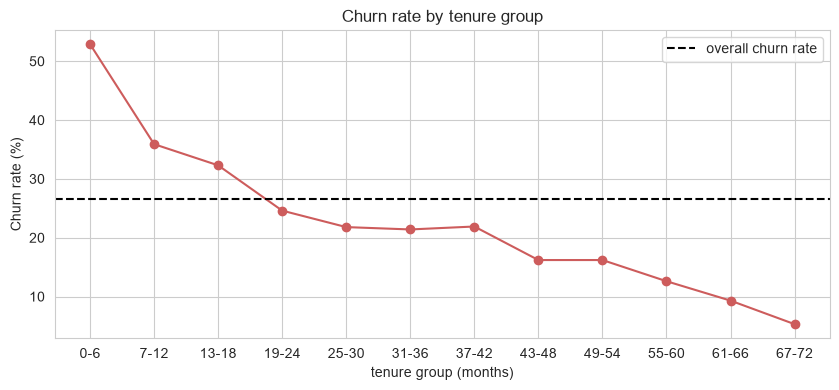

In [14]:
bins = [-1, 6, 12, 18, 24, 30, 36, 42, 48, 54, 60, 66, 72]
labels = ["0-6", "7-12", "13-18", "19-24", "25-30", "31-36", "37-42", "43-48", "49-54", "55-60", "61-66", "67-72"]
tenure_group = pd.cut(df["tenure"], bins=bins, labels=labels)

by_tenure = pd.DataFrame({"customers": tenure_group.value_counts().reindex(labels),
                          "churn_rate": (y.groupby(tenure_group, observed=True).mean() * 100).reindex(labels).round(1)})
print(by_tenure)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(labels, by_tenure["churn_rate"], marker="o", color="indianred")
ax.axhline(overall, color="black", linestyle="--", label="overall churn rate")
ax.set_xlabel("tenure group (months)")
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn rate by tenure group")
ax.legend()
plt.show()

**What the code does:** It cuts tenure into twelve groups of six months, calculates the number of customers and the churn rate in each group, and draws the churn rate as a line with a dashed line at the overall rate.

**Why this method was used:** A line plot is the right choice for an ordered variable such as tenure, because it shows the trend. Six month groups are wide enough to have a reasonable number of customers in each, and narrow enough to show the shape.

**What the output means:** The churn rate is highest in the first group, above 50%, and then falls steadily along the groups to under 10% in the last groups. The line crosses the overall rate at about the second year.

**Insights:** Most churn happens early in the customer life. A customer who has stayed more than about two years is much less likely to leave. So the first year is the most important period for retention, and the priority segment is new customers, especially those on month-to-month contracts.

**Effect on the ML pipeline:** This is a strong, almost monotonic relationship between a feature and the target, which a model can learn easily. A tenure group feature could also be used. It also means that the model is partly learning that new customers leave, and any change in the share of new customers will change the base churn rate.

## 7. Optional: Regression Target Preview (MonthlyCharges)

**Concept:** If the target were a number (for example, predicting MonthlyCharges), the analysis would cover the distribution: mean, median, variance, standard deviation, skewness and outliers. A skewed numerical target often needs a transformation, and outliers in a numerical target can strongly affect the model. This is only a preview of the method, since my real target is Churn.

**Example (business):** To predict house prices, the analyst checks the distribution of the price first. Prices are usually right-skewed, so a log transformation of the target often improves the model.

Mean: 64.76
Median: 70.35
Variance: 905.41
Standard deviation: 30.09
Skewness: -0.22
Excess kurtosis: -1.26
IQR outliers: 0


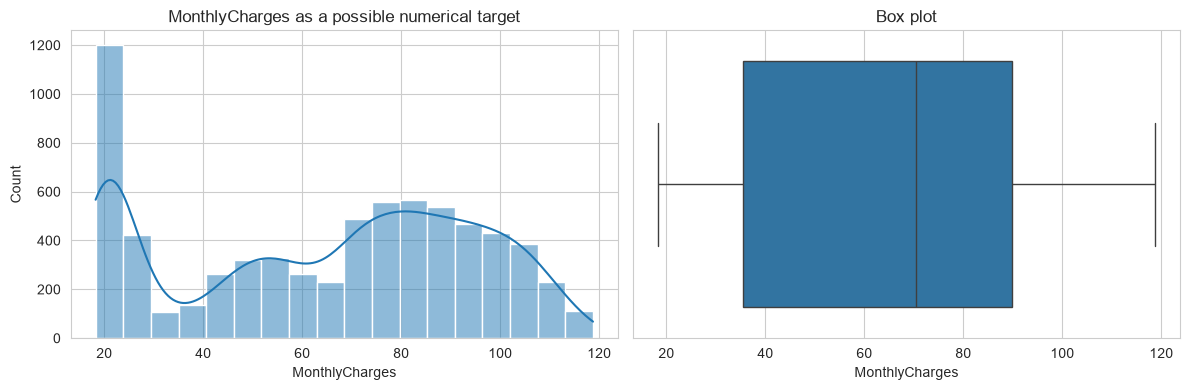

In [15]:
target_reg = df["MonthlyCharges"]

q1, q3 = target_reg.quantile(0.25), target_reg.quantile(0.75)
iqr = q3 - q1
n_out = ((target_reg < q1 - 1.5 * iqr) | (target_reg > q3 + 1.5 * iqr)).sum()

print("Mean:", round(target_reg.mean(), 2))
print("Median:", round(target_reg.median(), 2))
print("Variance:", round(target_reg.var(), 2))
print("Standard deviation:", round(target_reg.std(), 2))
print("Skewness:", round(target_reg.skew(), 2))
print("Excess kurtosis:", round(target_reg.kurt(), 2))
print("IQR outliers:", n_out)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(target_reg, kde=True, ax=axes[0])
axes[0].set_title("MonthlyCharges as a possible numerical target")
sns.boxplot(x=target_reg, ax=axes[1])
axes[1].set_title("Box plot")
plt.tight_layout()
plt.show()

**What the code does:** It calculates the mean, median, variance, standard deviation, skewness, kurtosis and the number of IQR outliers of MonthlyCharges, and draws a histogram and a box plot.

**Why this method was used:** These are exactly the measures the assignment lists for a regression target, so this shows the method on a numerical column of my dataset.

**What the output means:** The mean is about 65 and the median is about 70, the standard deviation is about 30 (variance about 905), the skewness is about -0.22, the kurtosis is about -1.3, and there are no IQR outliers. The histogram shows a peak near 20 and a wider group between 70 and 100.

**Insights:** As a regression target MonthlyCharges would be nearly symmetric with no outliers, but it has more than one peak, which comes from the different internet service types. A model would need InternetService to explain this shape.

**Effect on the ML pipeline:** This target would not need outlier removal or a skew transformation, but a model for it should include the service features. For my actual project this is not needed, since the project target is Churn.

# Findings

| Question | Finding |
|---|---|
| Target type | Binary classification (Churn: No or Yes) |
| Class counts | No about 5174, Yes about 1869 |
| Class percentages | About 73.5% and 26.5% |
| Imbalance ratio | About 2.8 to 1, a mild to moderate imbalance |
| Target quality | No missing values, no blank values, only two labels, no duplicate customers |
| Accuracy baseline | Always predicting No gives about 73.5% accuracy but 0 recall |
| Simple rule baseline | Predicting churn for all month-to-month customers gives about 65% accuracy but about 88% recall and about 43% precision |
| Churn over tenure | Highest in the first months (above 50%) and falls to under 10% for long term customers |

# Summary

- The target is clean and binary, with 26.5% of customers in the positive (churn) class.
- The imbalance is not extreme but is enough to make accuracy a misleading metric.
- Two naive baselines show the metrics to beat: about 73.5% accuracy for always No, and about 88% recall for the contract rule.
- Churn is strongly concentrated in the early months of the customer life.
- The regression analysis of a numerical target does not apply to Churn. The preview of MonthlyCharges shows how it would be done.

**Points for later sprints**
1. Convert the target to 0 and 1 with Yes as the positive class.
2. Use a stratified train and test split and stratified cross validation.
3. Use precision, recall, F1 and ROC AUC, and not accuracy alone.
4. Consider class weights, resampling or threshold tuning if the minority recall is low.
5. Use the two naive baselines as the minimum performance for any model.

**What I learned:** A high accuracy can mean nothing when the classes are imbalanced, as the always No model shows. Looking at how the target changes with a key feature, such as tenure, tells the business story before any model is built.

Next: `11_EDA_Visualization.ipynb`